# 5.1 Column types and how beams load columns

Column classification, effective length, and the load take-down for the three typical columns: **B2** (internal), **B1** (edge), **A1** (corner).

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

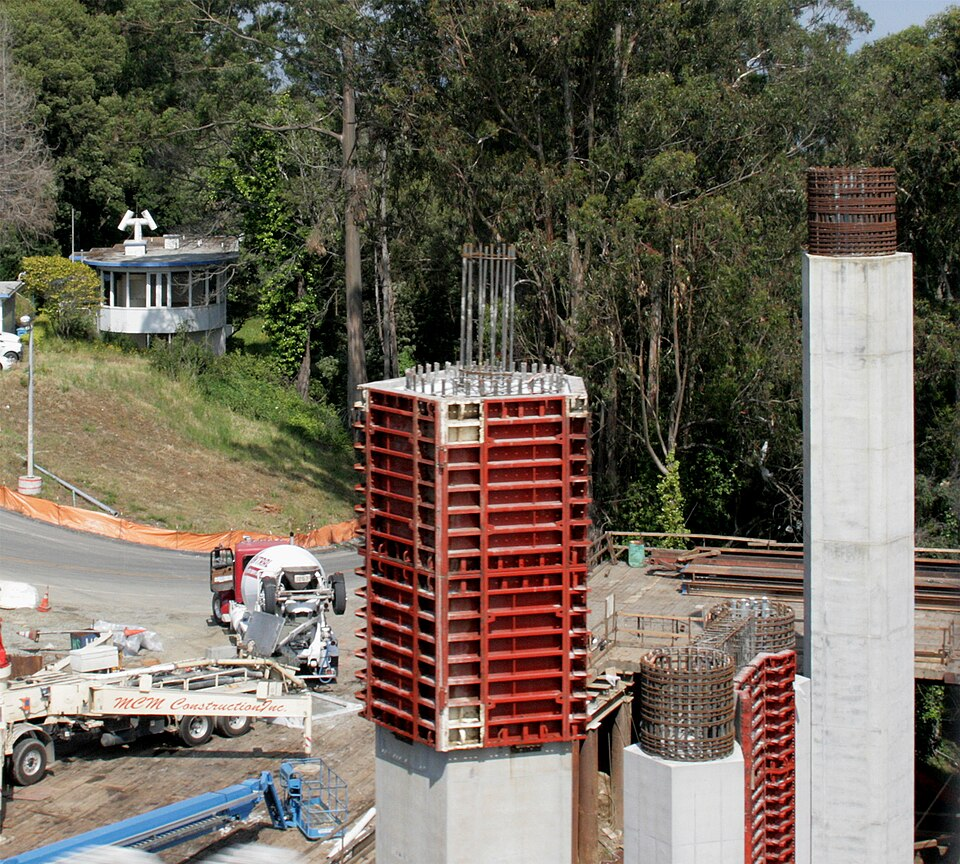

*Column formwork with the reinforcement projecting for the next lift.* <br><small>Photo: Leonard G., [CC0](http://creativecommons.org/publicdomain/zero/1.0/deed.en), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:SFOBBESR_ColumnFormworkAdj7June2011.jpg).</small>

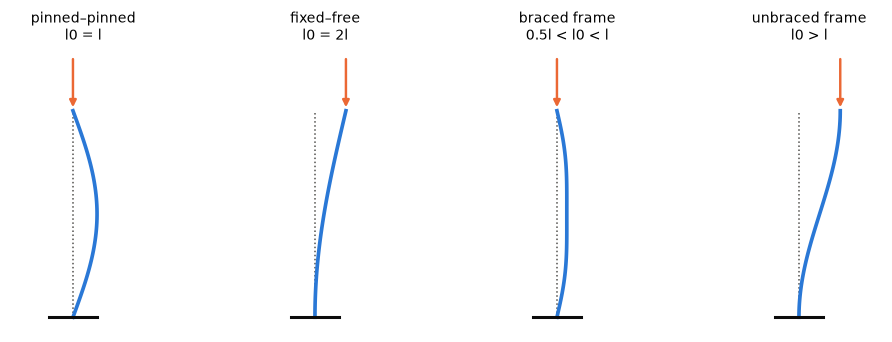

In [2]:
photo("column_formwork", "Column formwork with the reinforcement projecting for the next lift.")
P.sketch_columns()

## Types of column

| Classified by | Types | EC2 reference |
|:--|:--|:--|
| Proportions | Column if h ≤ 4b and height ≥ 3h; otherwise a wall | 5.3.1(7) |
| Lateral stability | **Braced** (walls/core resist sway) or **unbraced** | 5.8.1, Fig. 5.7 |
| Slenderness | **Stocky/short** if λ ≤ λ<sub>lim</sub>; **slender** otherwise | 5.8.3.1 |
| Loading | Axial (with minimum eccentricity), axial + uniaxial bending, axial + biaxial bending | 6.1, 5.8.9 |
| Reinforcement | Tied (links) or spiral/circular | 9.5.3 |

## Effective length (EC2 5.8.3.2)

$$\text{Braced: } l_0 = 0.5l\sqrt{\left(1+\frac{k_1}{0.45+k_1}\right)\left(1+\frac{k_2}{0.45+k_2}\right)}$$

$$\text{Unbraced: } l_0 = l\cdot\max\left\{\sqrt{1+10\frac{k_1k_2}{k_1+k_2}};\;\left(1+\frac{k_1}{1+k_1}\right)\left(1+\frac{k_2}{1+k_2}\right)\right\}$$

$k = (\theta/M)(EI/l)$: 0 = rigid, ∞ = pinned, minimum 0.1 recommended. With cracked beams, $k = \sum(EI/l)_{col}\big/\sum 2(EI/l)_{beam}$ (the beam stiffness used in JRC EUR 26566, 3.2).

## Slenderness limit (EC2 5.8.3.1)

$$\lambda = \frac{l_0}{i}, \qquad \lambda_{lim} = \frac{20\,A\,B\,C}{\sqrt n}, \quad n = \frac{N_{Ed}}{A_cf_{cd}}, \quad A=\frac{1}{1+0.2\varphi_{ef}}\ (0.7),\; B=\sqrt{1+2\omega}\ (1.1),\; C=1.7-r_m\ (0.7)$$

## Design moments, braced columns

| | Moment |
|:--|:--|
| Imperfection | $e_i = l_0/400$ (EC2 5.2(9)) |
| Minimum | $M_{min} = N_{Ed}e_0$, $e_0=\max(h/30,\,20\text{ mm})$ (EC2 6.1(4)) |
| Stocky | $M_{Ed}=\max(M_{02},\,M_{min})$ |
| Slender | $M_{Ed}=\max(M_{02},\;M_{0e}+M_2,\;M_{01}+0.5M_2,\;M_{min})$ with $M_2=N_{Ed}e_2$ (EC2 5.8.8; the $M_{01}+0.5M_2$ term is BS 8110-1 3.8.3.2 c)) |

No moment redistribution is used for columns (EC2 5.5(6)).

## Load take-down

Each suspended level delivers the reactions of the two beams meeting at the column. Imposed-load reduction factors (EN 1991-1-1 6.3.1.2) are **not** applied, which is conservative.

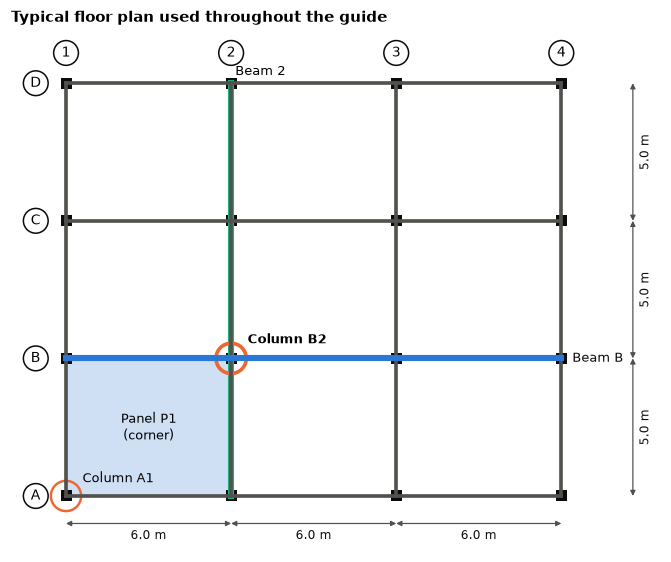

## Column B2 (internal)

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Column B2, ground storey

| Reference | Calculation | Output |
|:--|:--|:--|
| Analysis (Notebook 4.2) | Beam B reaction, permanent, per level: $G_{1}$ | $G_{1} = 143.6$ kN |
|  | Beam B reaction, variable: $Q_{1}$ | $Q_{1} = 82.49$ kN |
|  | Beam 2 reaction, permanent, per level: $G_{2}$ | $G_{2} = 103$ kN |
|  | Beam 2 reaction, variable: $Q_{2}$ | $Q_{2} = 57.95$ kN |
|  | Suspended levels: $N_{lev}$ | $N_{lev} = 3$  |
|  | $c$ | $c = 350$ mm |
|  | $H$ | $H = 3.5$ m |
| EN 1991-1-1 Table A.1 | Column self-weight<br>$G_{sw} = 25\,\left(\dfrac{c}{1000}\right)^{2}\,H\,N_{lev}$<br>$\quad = 25\times \left(\dfrac{350}{1000}\right)^{2}\times 3.5\times 3$ | $\mathbf{G_{sw} = 32.16}$ kN |
|  | $G_{k} = N_{lev}\,\left(G_{1} + G_{2}\right) + G_{sw}$<br>$\quad = 3\times \left(143.6 + 103\right) + 32.16$ | $\mathbf{G_{k} = 772}$ kN |
|  | $Q_{k} = N_{lev}\,\left(Q_{1} + Q_{2}\right)$<br>$\quad = 3\times \left(82.49 + 57.95\right)$ | $\mathbf{Q_{k} = 421.3}$ kN |
| EN 1990 Exp. (6.10) | $N_{Ed} = 1.35\,G_{k} + 1.5\,Q_{k}$<br>$\quad = 1.35\times 772 + 1.5\times 421.3$ | $\mathbf{N_{Ed} = 1674.2}$ kN |
| EN 1990 Exp. (6.14b) | Characteristic (for the footing)<br>$N_{k} = G_{k} + Q_{k}$<br>$\quad = 772 + 421.3$ | $\mathbf{N_{k} = 1193.4}$ kN |
|  | Tributary area: $A_{trib}$ | $A_{trib} = 30$ m² |
|  | $n_{k}$ | $n_{k} = 9.675$ kN/m²<br><small>(= 9675 Pa)</small> |
|  | Slab load by tributary area, for comparison<br>$N_{trib} = N_{lev}\,A_{trib}\,n_{k}$<br>$\quad = 3\times 30\times 9.675$ | $\mathbf{N_{trib} = 870.8}$ kN |
|  | The beam reactions exceed the tributary-area value because the first interior support of a continuous beam attracts more load. The larger value is used. |  |


## Column B1 (edge)

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Column B1, ground storey

| Reference | Calculation | Output |
|:--|:--|:--|
| Analysis (Notebook 4.2) | Beam B reaction, permanent, per level: $G_{1}$ | $G_{1} = 50.82$ kN |
|  | Beam B reaction, variable: $Q_{1}$ | $Q_{1} = 29.09$ kN |
|  | Beam 1 reaction, permanent, per level: $G_{2}$ | $G_{2} = 88.3$ kN |
|  | Beam 1 reaction, variable: $Q_{2}$ | $Q_{2} = 19.98$ kN |
|  | Suspended levels: $N_{lev}$ | $N_{lev} = 3$  |
|  | $c$ | $c = 350$ mm |
|  | $H$ | $H = 3.5$ m |
| EN 1991-1-1 Table A.1 | Column self-weight<br>$G_{sw} = 25\,\left(\dfrac{c}{1000}\right)^{2}\,H\,N_{lev}$<br>$\quad = 25\times \left(\dfrac{350}{1000}\right)^{2}\times 3.5\times 3$ | $\mathbf{G_{sw} = 32.16}$ kN |
|  | $G_{k} = N_{lev}\,\left(G_{1} + G_{2}\right) + G_{sw}$<br>$\quad = 3\times \left(50.82 + 88.3\right) + 32.16$ | $\mathbf{G_{k} = 449.5}$ kN |
|  | $Q_{k} = N_{lev}\,\left(Q_{1} + Q_{2}\right)$<br>$\quad = 3\times \left(29.09 + 19.98\right)$ | $\mathbf{Q_{k} = 147.2}$ kN |
| EN 1990 Exp. (6.10) | $N_{Ed} = 1.35\,G_{k} + 1.5\,Q_{k}$<br>$\quad = 1.35\times 449.5 + 1.5\times 147.2$ | $\mathbf{N_{Ed} = 827.7}$ kN |
| EN 1990 Exp. (6.14b) | Characteristic (for the footing)<br>$N_{k} = G_{k} + Q_{k}$<br>$\quad = 449.5 + 147.2$ | $\mathbf{N_{k} = 596.7}$ kN |


## Column A1 (corner)

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Column A1, ground storey

| Reference | Calculation | Output |
|:--|:--|:--|
| Analysis (Notebook 4.2) | Beam A reaction, permanent, per level: $G_{1}$ | $G_{1} = 40.71$ kN |
|  | Beam A reaction, variable: $Q_{1}$ | $Q_{1} = 10.13$ kN |
|  | Beam 1 reaction, permanent, per level: $G_{2}$ | $G_{2} = 31.84$ kN |
|  | Beam 1 reaction, variable: $Q_{2}$ | $Q_{2} = 7.092$ kN |
|  | Suspended levels: $N_{lev}$ | $N_{lev} = 3$  |
|  | $c$ | $c = 350$ mm |
|  | $H$ | $H = 3.5$ m |
| EN 1991-1-1 Table A.1 | Column self-weight<br>$G_{sw} = 25\,\left(\dfrac{c}{1000}\right)^{2}\,H\,N_{lev}$<br>$\quad = 25\times \left(\dfrac{350}{1000}\right)^{2}\times 3.5\times 3$ | $\mathbf{G_{sw} = 32.16}$ kN |
|  | $G_{k} = N_{lev}\,\left(G_{1} + G_{2}\right) + G_{sw}$<br>$\quad = 3\times \left(40.71 + 31.84\right) + 32.16$ | $\mathbf{G_{k} = 249.8}$ kN |
|  | $Q_{k} = N_{lev}\,\left(Q_{1} + Q_{2}\right)$<br>$\quad = 3\times \left(10.13 + 7.092\right)$ | $\mathbf{Q_{k} = 51.65}$ kN |
| EN 1990 Exp. (6.10) | $N_{Ed} = 1.35\,G_{k} + 1.5\,Q_{k}$<br>$\quad = 1.35\times 249.8 + 1.5\times 51.65$ | $\mathbf{N_{Ed} = 414.7}$ kN |
| EN 1990 Exp. (6.14b) | Characteristic (for the footing)<br>$N_{k} = G_{k} + Q_{k}$<br>$\quad = 249.8 + 51.65$ | $\mathbf{N_{k} = 301.4}$ kN |


In [3]:
P.sketch_plan()
for col, desc in (("B2", "internal"), ("B1", "edge"), ("A1", "corner")):
    t = PJ.takedown(col); (l1, _), (l2, _) = PJ.COLUMNS[col]
    s = Sheet(f"Column {col} ({desc})", element=f"Column {col}, ground storey")
    s.let("G_1", t["g1"], "kN", f"Beam {l1} reaction, permanent, per level", "Analysis (Notebook 4.2)"); s.let("Q_1", t["q1"], "kN", f"Beam {l1} reaction, variable")
    s.let("G_2", t["g2"], "kN", f"Beam {l2} reaction, permanent, per level"); s.let("Q_2", t["q2"], "kN", f"Beam {l2} reaction, variable")
    s.let("N_lev", BRIEF["levels"], "", "Suspended levels"); s.let("c", BRIEF["col"][0], "mm"); s.let("H", BRIEF["storey"], "m")
    s.calc("G_sw", "25*(c/1000)**2*H*N_lev", "kN", "EN 1991-1-1 Table A.1", "Column self-weight")
    s.calc("G_k", "N_lev*(G_1 + G_2) + G_sw", "kN"); s.calc("Q_k", "N_lev*(Q_1 + Q_2)", "kN")
    s.calc("N_Ed", "1.35*G_k + 1.5*Q_k", "kN", "EN 1990 Exp. (6.10)"); s.calc("N_k", "G_k + Q_k", "kN", "EN 1990 Exp. (6.14b)", "Characteristic (for the footing)")
    if col == "B2":
        g, q = PJ.area_loads(); s.let("A_trib", BRIEF["lx_bay"] * BRIEF["ly_bay"], "m²", "Tributary area"); s.let("n_k", g + q, "kN/m²")
        s.calc("N_trib", "N_lev*A_trib*n_k", "kN", "", "Slab load by tributary area, for comparison"); s.note("The beam reactions exceed the tributary-area value because the first interior support of a continuous beam attracts more load. The larger value is used.")
    s.show()

## Moments from the beams

BS 8110-1 3.2.1.2.5: one joint, remote ends fixed, beams at half stiffness, one span fully loaded and the other with permanent load only. Half the moment carries over to the column base.

In [4]:
rows = []
for col, (a, b) in PJ.COLUMNS.items():
    for ln, j in (a, b):
        r = PJ.column_joint(ln, j); rows.append([col, f"Beam {ln}", round(r["f1"], 1), round(r["f2"], 1), round(r["dM"], 1), round(r["M"], 1), round(r["M"] / 2, 1)])
table(rows, ["Column", "From", "FEM 1", "FEM 2", "Out of balance", "Column top (kN·m)", "Column base (kN·m)"], "ULS moments in the ground-storey column")

**ULS moments in the ground-storey column**

| Column | From | FEM 1 | FEM 2 | Out of balance | Column top (kN·m) | Column base (kN·m) |
|:--|:-:|:-:|:-:|:-:|:-:|:-:|
| B2 | Beam B | 176.2 | 100.1 | 76.1 | 14.9 | 7.5 |
| B2 | Beam 2 | 105.5 | 59 | 46.5 | 8.4 | 4.2 |
| B1 | Beam B | 176.2 | 0 | 176.2 | 49.3 | 24.6 |
| B1 | Beam 1 | 63.1 | 47.5 | 15.6 | 3.1 | 1.6 |
| A1 | Beam A | 100.2 | 0 | 100.2 | 30.1 | 15.1 |
| A1 | Beam 1 | 63.1 | 0 | 63.1 | 17.9 | 8.9 |


Edge and corner columns carry little load but large moments. Internal columns carry large loads and small moments.